# 02 | BOLD time series → functional connectivity

**Learning goals:** inspect motion, censoring, nuisance regression, degrees of freedom, signed correlations and analysis sensitivity.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## FC is a statistical association
For parcel signals $x_i(t)$, $r_{ij}=\mathrm{corr}(x_i,x_j)$. A correlation is neither a tract nor a causal connection. Tumour-related neurovascular uncoupling can alter BOLD even when neural signalling is preserved.

BOLD now receives susceptibility correction from the same-session DWI AP/PA topup field. A rigid, mutual-information fit transfers undistorted b0/Hz data into the BOLD reference, with two fixed refinement rounds after the initial fit. BOLD is `j-` with readout 0.01464 s. A signed voxel shift is $s=\mathrm{PEsign}\times f_{Hz}\times T_{ro}$. Saved rigid motion maps output coordinates into each raw frame; the PE shift is then applied along that raw frame's voxel axis. Cubic sampling occurs once, with the Jacobian determinant of the composed pull.

The field is a static cross-acquisition approximation: DWI starts about 9–10 minutes after BOLD, no shim settings or BOLD-specific reversed-PE scan are supplied, and GE-EPI signal dropout is not recovered. Readout metadata are inconsistent. The primary uses the supplied BOLD/DWI readout ratio; an alternative uses echo spacing × (phase lines − 1) for both acquisitions, giving **0.761 times** the primary displacement. Registration is held fixed for this amplitude sensitivity. It does not cover all uncertainty in the field fit.

All 180 frames are spatially processed using the existing motion estimates. Positive Jacobians, field support and in-bounds sampling across all frames define a valid mask. The corrected mean is registered to T1 again, and atlas sampling, tissue-PC nuisance estimates and FC are recomputed. The prior rigid-only BOLD/FC is preserved under `results/bold_uncorrected`; SC remains unchanged. Slice timing and motion-dependent changes in the field remain uncorrected.

We realign all 180 frames to an early-run mean, drop the first 4 frames and censor approximate framewise displacement (FD)>0.5 mm plus the following frame. FD sums translation changes and absolute Euler-angle changes at a 50-mm head radius.

ROI means use cortical voxels with tSNR>5 outside the pre-op lesion footprint in both sessions; require ≥8 usable voxels. Primary nuisance regression uses 24 motion terms, five PCs from combined session-specific T1 WM/CSF cores (PVE≥0.95, native erosion and valid BOLD support), a linear trend and DCT terms below 0.01 Hz. Temporal projection, voxel scaling and PCA are trained only on retained original indices. Joint final regression preserves these indices. This custom CompCor-inspired recipe is a post hoc methodological recommendation; it is not independently validated tissue segmentation or an optimal patient-specific model. See `config/PRIMARY_DENOISING.md` and notebook 06 for rationale and sensitivities. Notebook [07](07_censoring_motion_duration_and_coupling.ipynb) investigates why strict censoring changes coupling, using matched duration/FD, run-half and nuisance-refitting controls. Primary FC has **no low-pass filter and no global signal regression**. A 0.01–0.1-Hz band-pass is a sensitivity analysis with an explicit residual-df guard.

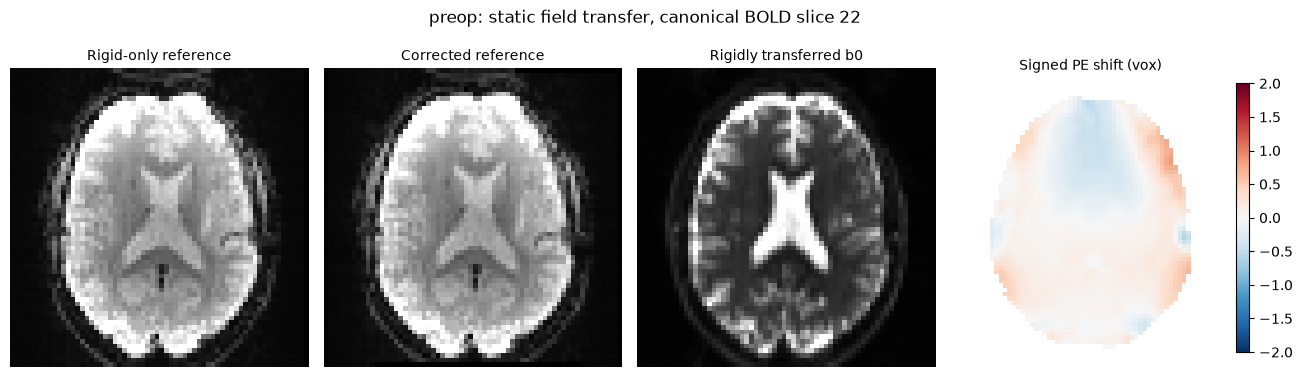

interactive(children=(Dropdown(description='session', options=('preop', 'postop'), value='preop'), IntSlider(v…

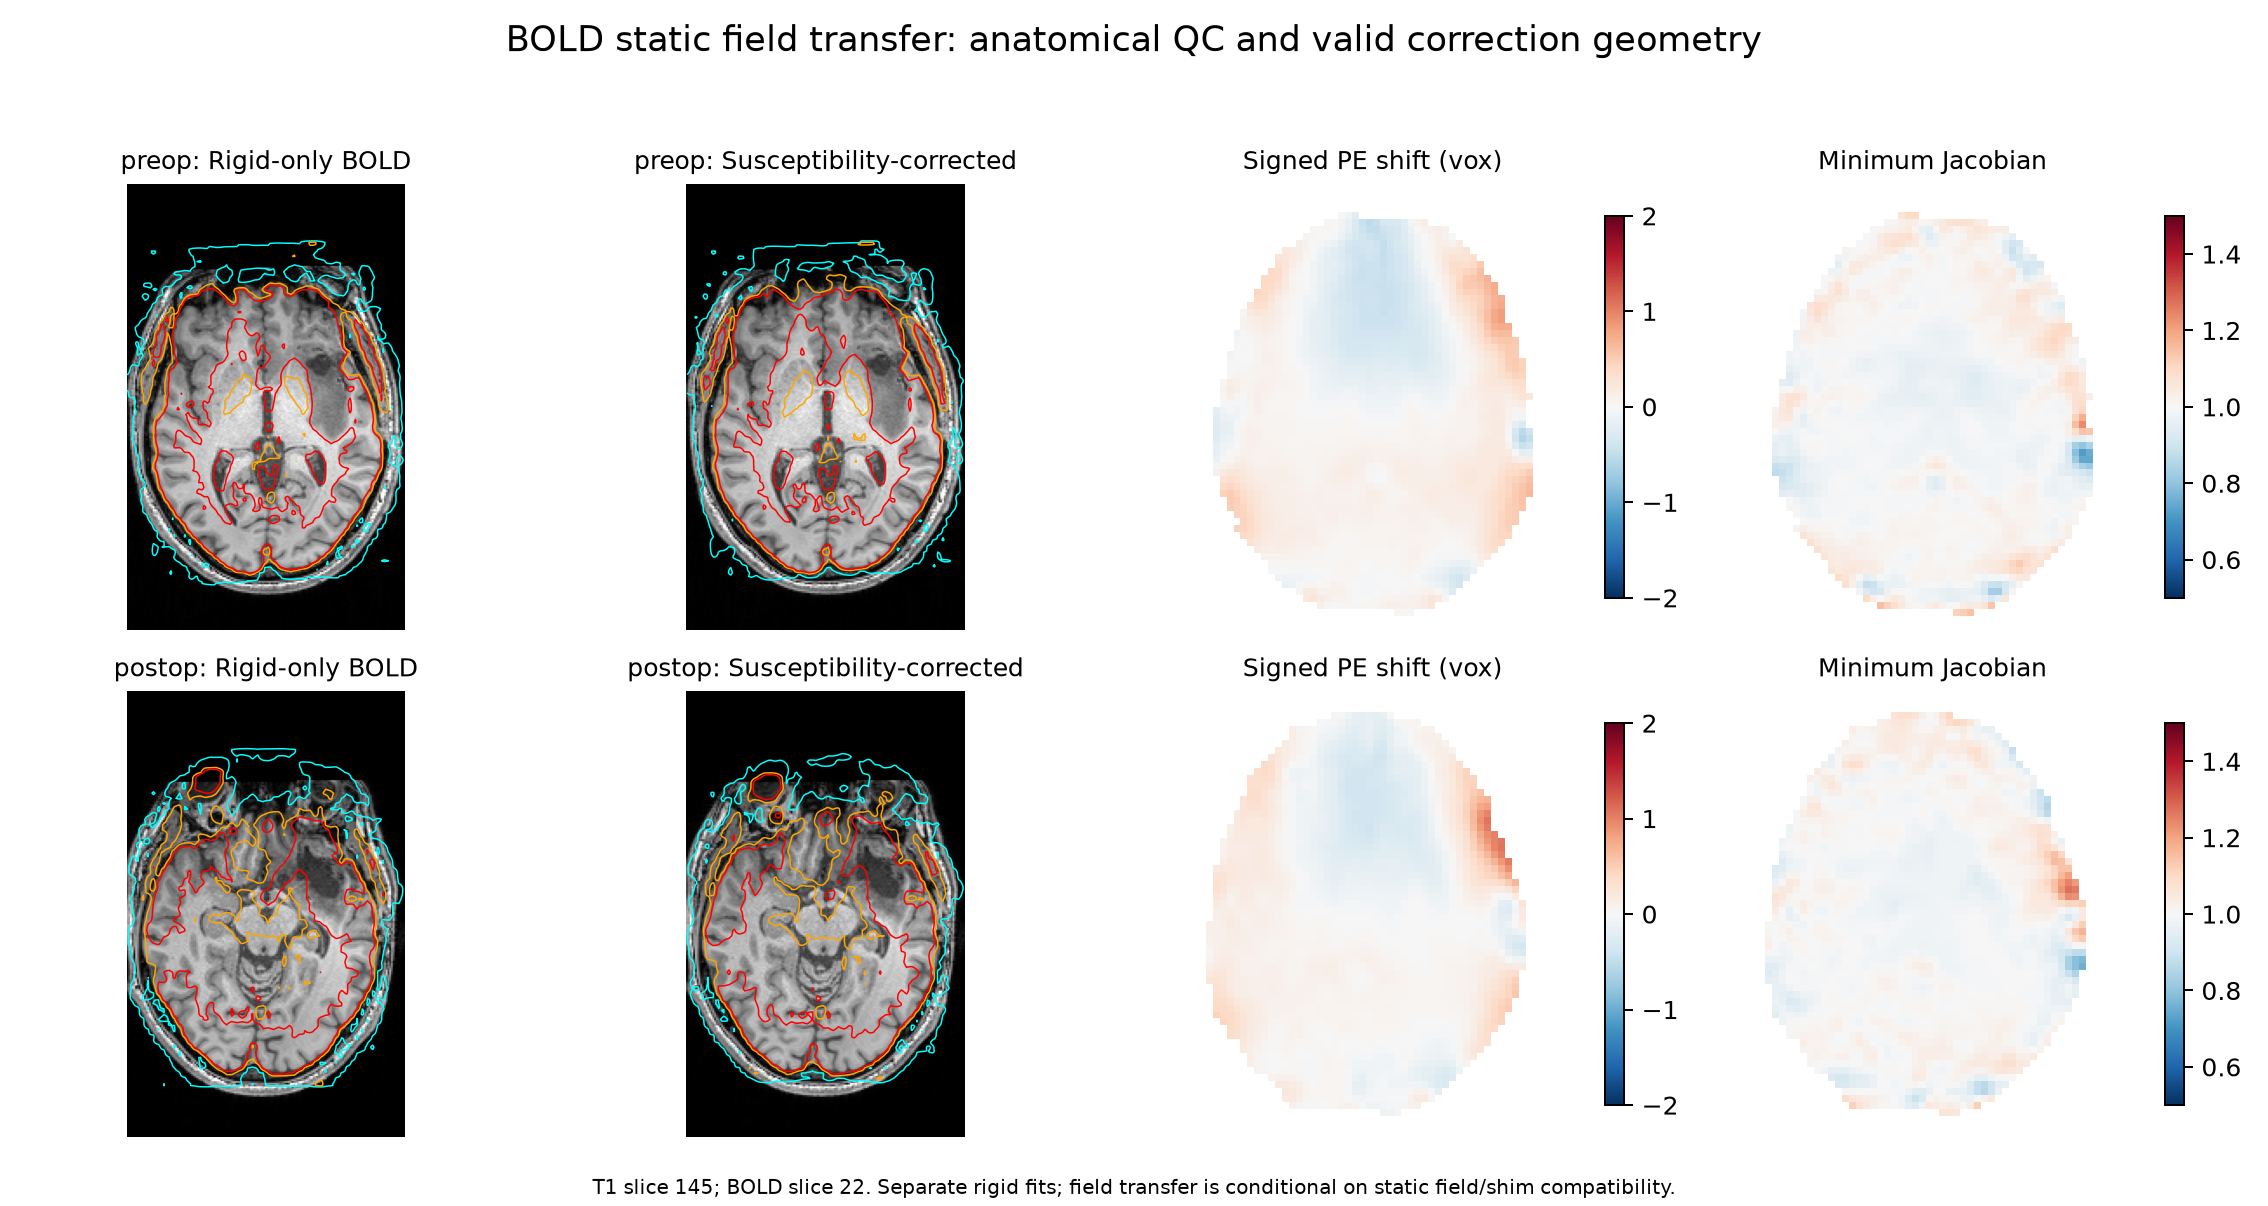

In [2]:
display(pd.read_csv(RESULTS/"bold_correction_qc.csv"))
from pat16.views import show_bold_correction
widgets.interact(show_bold_correction,session=widgets.Dropdown(options=SESSIONS),z=widgets.IntSlider(min=5,max=36,value=22))
display(Image(filename=str(RESULTS/"figures/bold_distortion_qc.png")))

## Separate spatial correction from nuisance-model sensitivity
Compare rigid-only BOLD, corrected BOLD and the alternative timing ratio below, all refitted with the SAME anatomical primary recipe. The original rigid-only FC archive is retained separately. All comparisons use the same intersected nodes, saved motion estimates, censoring rule and fixed SC. Spatial masks, interpolation and nuisance PCs are refitted, so their difference is a **processing-package sensitivity**, not the isolated effect or validation of an unwarping algorithm.

The separately labelled HISTORICAL noncortical component-swap diagnostic holds either ROI time series or its five PCs fixed. It does not use the current anatomical primary recipe. It reveals that the large postoperative mean-FC change is mainly associated with refitting noncortical nuisance PCs. These are not validated WM/CSF components. The swaps are diagnostic, not independently preferred physiological models. A direction or magnitude of FC change cannot be attributed to surgery or better neural recovery from this exercise.

,session,BOLD_processing,denoising_model,common_nodes,mean_fc_r,mean_absolute_fc_difference_from_uncorrected,sc_fc_spearman,retained_frames,residual_df,nodes,edges,density,components,largest_component,binary_global_efficiency,weighted_global_efficiency,weighted_clustering,mean_strength,weight_scale,SC_reference
0,preop,uncorrected,anatomical5,100,0.100290,0.000000,0.183942,146,107,100,990,0.2,1,100,0.557626,0.221501,0.213466,7.728157,1.0,repeat80-mean-seed-rate-common-coupling-v1
1,preop,corrected,anatomical5,100,0.087228,0.050975,0.188216,146,107,100,990,0.2,1,100,0.557879,0.213575,0.199240,7.460088,1.0,repeat80-mean-seed-rate-common-coupling-v1
2,preop,readout_alternative,anatomical5,100,0.088792,0.051617,0.185762,146,107,100,990,0.2,1,100,0.557660,0.214890,0.202041,7.529162,1.0,repeat80-mean-seed-rate-common-coupling-v1
3,postop,uncorrected,anatomical5,100,0.047990,0.000000,0.146303,150,111,100,990,0.2,1,100,0.573030,0.196071,0.154322,6.619263,1.0,repeat80-mean-seed-rate-common-coupling-v1
4,postop,corrected,anatomical5,100,0.045607,0.036100,0.146488,150,111,100,990,0.2,1,100,0.573754,0.193583,0.151840,6.509051,1.0,repeat80-mean-seed-rate-common-coupling-v1
5,postop,readout_alternative,anatomical5,100,0.044499,0.034703,0.145086,150,111,100,990,0.2,1,100,0.574495,0.192941,0.149594,6.482882,1.0,repeat80-mean-seed-rate-common-coupling-v1


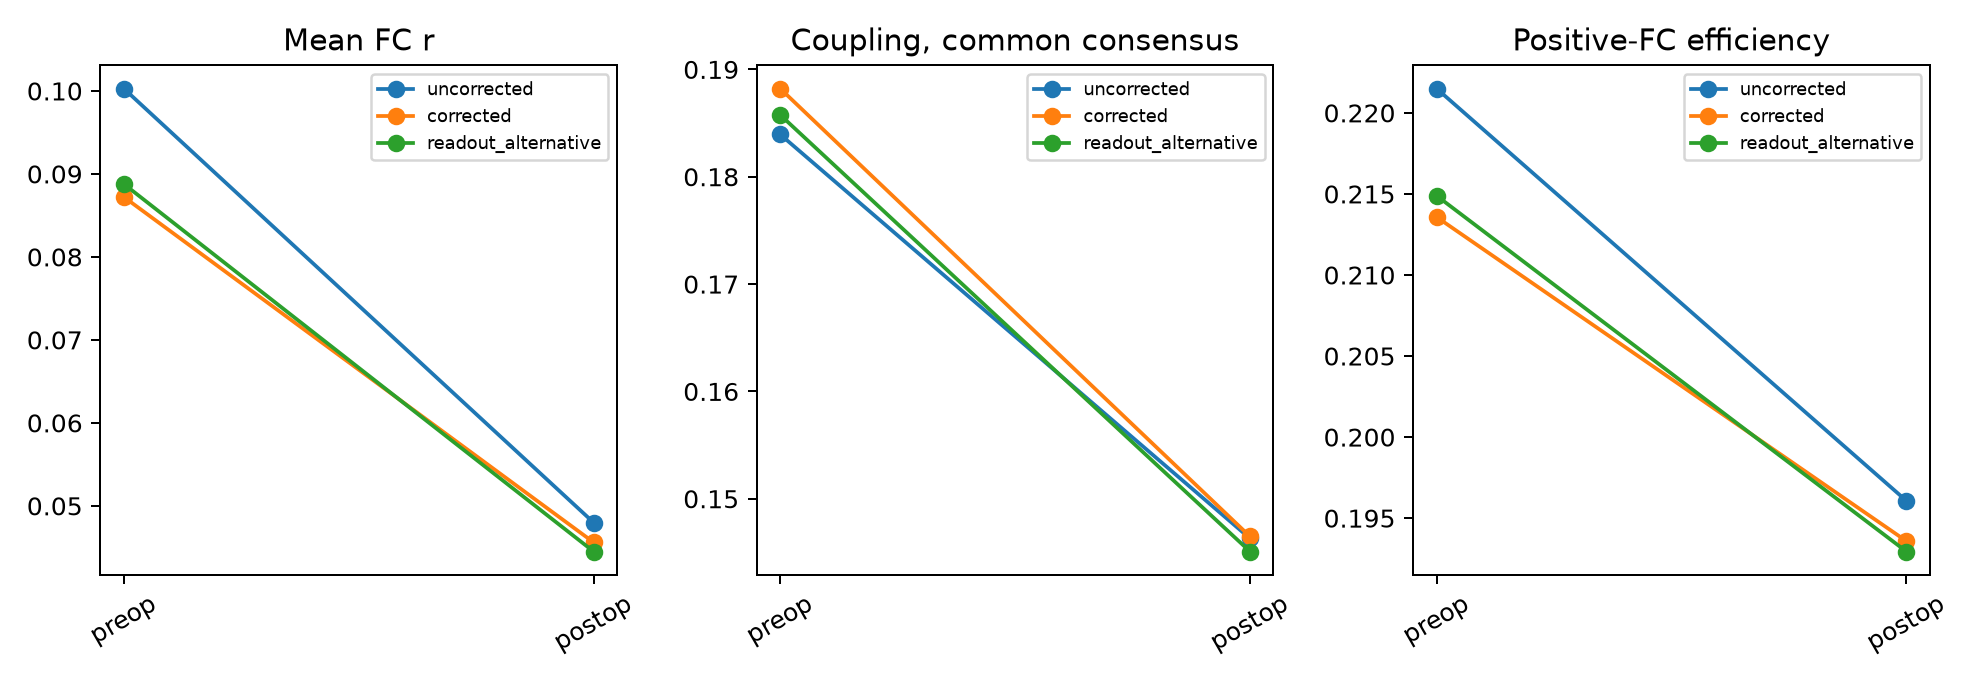

,session,diagnostic_model,ROI_processing,PC_processing,mean_fc_r,sc_fc_spearman,common_nodes
0,preop,historical_noncortical5,uncorrected,uncorrected,0.364645,0.203769,100
1,preop,historical_noncortical5,uncorrected,corrected,0.357976,0.202523,100
2,preop,historical_noncortical5,corrected,uncorrected,0.362943,0.193027,100
3,preop,historical_noncortical5,corrected,corrected,0.359665,0.194448,100
4,postop,historical_noncortical5,uncorrected,uncorrected,0.271927,0.169905,100
5,postop,historical_noncortical5,uncorrected,corrected,0.135131,0.197811,100
6,postop,historical_noncortical5,corrected,uncorrected,0.267861,0.158710,100
7,postop,historical_noncortical5,corrected,corrected,0.133487,0.187481,100


In [3]:
display(pd.read_csv(RESULTS/"primary_sc/bold_comparison.csv"))
display(Image(filename=str(RESULTS/"figures/primary_sc_bold.png")))
display(pd.read_csv(RESULTS/"bold_nuisance_sensitivity.csv"))

### Follow the mechanism in notebook 06
The postoperative five-PC cutoff includes a strongly cortical-mean-associated direction after refitting. A cubic **zero-field** resampling control reproduces much of this sensitivity, particularly with the new mask; it is not an isolated susceptibility effect. Notebook [06](06_nuisance_refitting_and_anatomical_denoising.ipynb) holds corrected cortical signals, motion and censoring fixed, sweeps PC count, and compares session-specific T1 WM/CSF models. Historical noncortical regression is retained as a sensitivity; the main analyses use retained-frame anatomical five-PC regression. Lower FC or greater variance removal is not physiological validation.

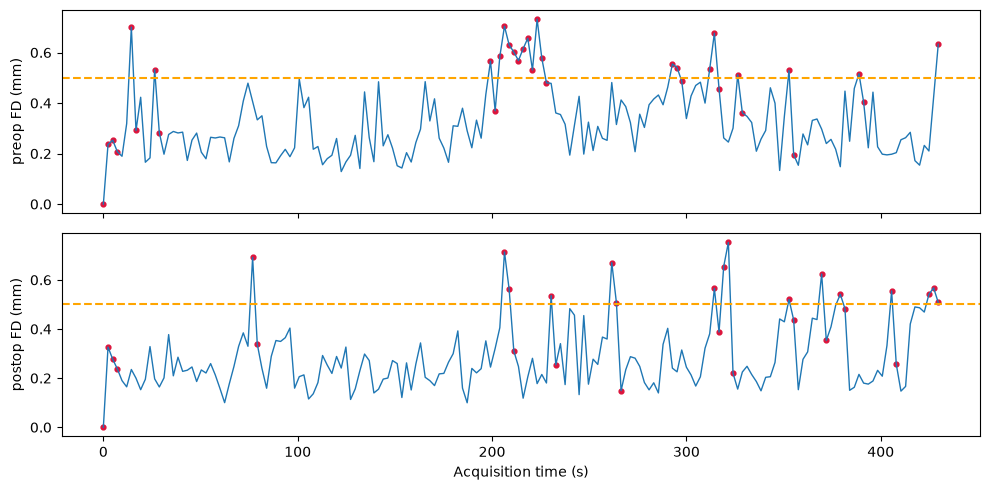

,retained_frames,retained_minutes,design_rank,residual_df,mean_fd_mm,max_fd_mm,fd_threshold_mm,valid_rois,global_signal_regression,analysis,low_pass_Hz,denoising_model,PCA_fit_frames,status
0,146.0,5.84,39.0,107.0,0.327879,0.731857,0.5,100.0,False,primary,NaN,anatomical5,146.0,NaN
1,68.0,2.72,39.0,29.0,0.327879,0.731857,0.3,100.0,False,fd03,NaN,anatomical5,68.0,NaN
2,176.0,7.04,39.0,137.0,0.327879,0.731857,1.0,100.0,False,fd10,NaN,anatomical5,176.0,NaN
3,146.0,5.84,40.0,106.0,0.327879,0.731857,0.5,100.0,True,gsr,NaN,anatomical5,146.0,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,bandpass,NaN,NaN,NaN,"Insufficient FC data: retained=146, residual d..."


,retained_frames,retained_minutes,design_rank,residual_df,mean_fd_mm,max_fd_mm,fd_threshold_mm,valid_rois,global_signal_regression,analysis,low_pass_Hz,denoising_model,PCA_fit_frames
0,150,6.00,39,111,0.287123,0.752623,0.5,100,False,primary,NaN,anatomical5,150
1,96,3.84,39,57,0.287123,0.752623,0.3,100,False,fd03,NaN,anatomical5,96
2,176,7.04,39,137,0.287123,0.752623,1.0,100,False,fd10,NaN,anatomical5,176
3,150,6.00,40,110,0.287123,0.752623,0.5,100,True,gsr,NaN,anatomical5,150
4,150,6.00,132,18,0.287123,0.752623,0.5,100,False,bandpass,0.1,anatomical5,150


In [4]:
fig,axs=plt.subplots(2,1,figsize=(10,5),sharex=True)
for ax,session in zip(axs,SESSIONS):
    fd=np.load(RESULTS/session/"fd.npy");keep=np.load(RESULTS/session/"fc_primary_keep.npy")
    ax.plot(np.arange(len(fd))*2.4,fd,lw=1);ax.scatter(np.where(~keep)[0]*2.4,fd[~keep],s=12,color="crimson");ax.axhline(.5,color="orange",ls="--");ax.set_ylabel(f"{session} FD (mm)")
axs[-1].set_xlabel("Acquisition time (s)");plt.tight_layout();plt.show()
for session in SESSIONS:display(pd.DataFrame(json.loads((RESULTS/session/"fc_qc.json").read_text())["analyses"]))

retained_frames                  146
retained_minutes                5.84
design_rank                       39
residual_df                      107
mean_fd_mm                  0.327879
max_fd_mm                   0.731857
fd_threshold_mm                  0.5
valid_rois                       100
global_signal_regression       False
dtype: object

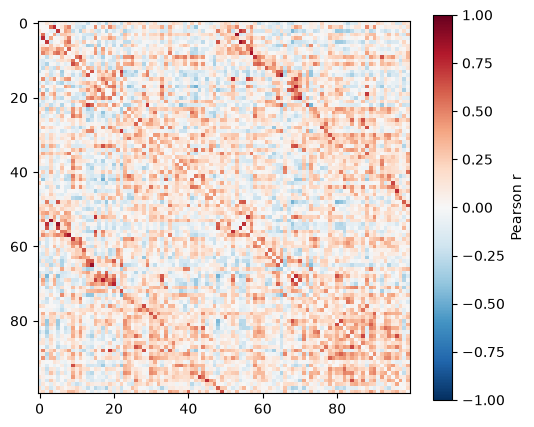

interactive(children=(Dropdown(description='session', options=('preop', 'postop'), value='preop'), SelectionSl…

<function __main__.denoising(session='preop', fd_threshold=0.5, low_pass='none', gsr=False)>

In [5]:
from pat16.denoising import primary_fit

def denoising(session="preop",fd_threshold=.5,low_pass="none",gsr=False):
    # Use the SAME whole-brain GSR signal and censor-specific PCA refit as saved analyses.
    gs=np.load(RESULTS/session/"primary_global_signal.npy") if gsr else None
    try:
        fc,res,keep,q,fd=primary_fit(session,fd_threshold,gs,low_pass=.1 if low_pass=="0.1 Hz" else None)
    except RuntimeError as e:
        print("QC guard:",e);return
    display(pd.Series(q));fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(fc,vmin=-1,vmax=1,cmap="RdBu_r");fig.colorbar(im,ax=ax,label="Pearson r");plt.show()
widgets.interact(denoising,session=widgets.Dropdown(options=SESSIONS),fd_threshold=widgets.SelectionSlider(options=[.3,.5,1.],value=.5),low_pass=widgets.Dropdown(options=["none","0.1 Hz"]),gsr=False)

## Sampling uncertainty is not a surgery-effect confidence interval
The main network stability summary now uses 200 nonreplacement 97-frame subsets from ten-frame original-time tiles, with complete WM/CSF nuisance training refitted (notebook 14). The earlier 200 moving-block bootstrap summaries with nuisance fits held fixed remain sensitivity evidence in the original CSV tables. This probes within-run sampling instability; it does not capture registration error, neurovascular changes, acquisition variability or practice effects.

**Exercise:** compare GSR, stricter FD and the band-pass guard. Do regional trends survive? Low residual degrees of freedom should cause abstention, not a lower QC threshold. The tables retain missing values rather than replacing absent nodes with zero.

In [6]:
display(pd.read_csv(RESULTS/"sensitivity.csv").query("analysis in ['primary','fd03','fd10','gsr']").dropna(axis=1,how="all"))
display(pd.read_csv(RESULTS/"preop/fc_roi_coverage.csv").merge(nodes[["id","label","lesion_overlap_fraction"]],on="id").sort_values("usable_fraction").head(15))

,session,analysis,mean_fc_r,sc_fc_spearman,SC_reference
0,preop,primary,0.087228,0.188216,repeat80-mean-seed-rate-common-coupling-v1
1,preop,fd03,0.108481,0.160765,repeat80-mean-seed-rate-common-coupling-v1
2,preop,fd10,0.071347,0.202076,repeat80-mean-seed-rate-common-coupling-v1
3,preop,gsr,0.002591,0.177879,repeat80-mean-seed-rate-common-coupling-v1
8,postop,primary,0.045607,0.146488,repeat80-mean-seed-rate-common-coupling-v1
9,postop,fd03,0.041219,0.126526,repeat80-mean-seed-rate-common-coupling-v1
10,postop,fd10,0.054110,0.135607,repeat80-mean-seed-rate-common-coupling-v1
11,postop,gsr,-0.000168,0.134444,repeat80-mean-seed-rate-common-coupling-v1


,id,atlas_voxels,usable_voxels,usable_fraction,label,lesion_overlap_fraction
75,76,392,102,0.260204,7Networks_RH_SalVentAttn_FrOperIns_1,0.725410
93,94,201,94,0.467662,7Networks_RH_Default_PFCv_1,0.508804
78,79,494,242,0.489879,7Networks_RH_Limbic_OFC_1,0.313091
79,80,798,435,0.545113,7Networks_RH_Limbic_TempPole_1,0.254221
32,33,406,240,0.591133,7Networks_LH_Limbic_TempPole_2,0.000000
59,60,137,83,0.605839,7Networks_RH_SomMot_2,0.368520
74,75,261,165,0.632184,7Networks_RH_SalVentAttn_TempOccPar_2,0.000000
60,61,164,104,0.634146,7Networks_RH_SomMot_3,0.222448
90,91,457,292,0.638950,7Networks_RH_Default_Temp_1,0.000000
91,92,267,176,0.659176,7Networks_RH_Default_Temp_2,0.288908
